### Load the data

In [1]:
import pandas as pd;
import matplotlib.pyplot as plt;
%matplotlib inline

In [2]:
path = r"C:\Users\Mohd Anas Ansari\Desktop\project\data\raw\Sample - Superstore.csv"
df = pd.read_csv(path, encoding="latin1")
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df.shape

(9994, 21)

In [3]:
# df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

### data quality check

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [5]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df[["Order Date", "Year", "Month", "Month Name"]].head()

,Order Date,Year,Month,Month Name
0,2016-11-08,2016,11,November
1,2016-11-08,2016,11,November
2,2016-06-12,2016,6,June
3,2015-10-11,2015,10,October
4,2015-10-11,2015,10,October


In [6]:
df["Postal Code"] = df["Postal Code"].astype(str).str.zfill(5)
df["Postal Code"].str.len().value_counts()

Postal Code
5    9994
Name: count, dtype: int64

In [7]:
print(df[["Sales", "Profit"]].sum().round(2))
print(df.dtypes)

Sales     2297200.86
Profit     286397.02
dtype: float64
Row ID                    int64
Order ID                 object
Order Date       datetime64[ns]
Ship Date        datetime64[ns]
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code              object
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
Year                      int32
Month                     int32
Month Name               object
dtype: object


In [8]:
out_path = r"C:\Users\Mohd Anas Ansari\Desktop\project\data\cleaned\cleaned_superstore.csv"
df.to_csv(out_path, index=False, encoding="utf-8-sig")
print("Saved:", out_path)

Saved: C:\Users\Mohd Anas Ansari\Desktop\project\data\cleaned\cleaned_superstore.csv


In [9]:
import pandas as pd

path = r"C:\Users\Mohd Anas Ansari\Desktop\project\data\cleaned\cleaned_superstore.csv"
df = pd.read_csv(path, parse_dates=["Order Date", "Ship Date"])
print(df.shape)
df.head()

(9994, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month Name
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,November
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,November
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,June
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,October
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,October


In [10]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
margin = total_profit / total_sales * 100

print(f"Total Sales:   {total_sales:,.2f}")
print(f"Total Profit:  {total_profit:,.2f}")
print(f"Total Orders:  {total_orders}")
print(f"Profit Margin: {margin:.2f}%")

Total Sales:   2,297,200.86
Total Profit:  286,397.02
Total Orders:  5009
Profit Margin: 12.47%


In [11]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum().round(2)
cat = cat.sort_values("Sales", ascending=False)
cat

,Sales,Profit
Category,,
Technology,836154.03,145454.95
Furniture,741999.80,18451.27
Office Supplies,719047.03,122490.80


In [12]:
region = df.groupby("Region")[["Sales", "Profit"]].sum().round(2)
region = region.sort_values("Profit", ascending=False)
region

,Sales,Profit
Region,,
West,725457.82,108418.45
East,678781.24,91522.78
South,391721.90,46749.43
Central,501239.89,39706.36


In [13]:
sub = df.groupby("Sub-Category")["Profit"].sum().round(2).sort_values()
sub[sub < 0]

Sub-Category
Tables      -17725.48
Bookcases    -3472.56
Supplies     -1189.10
Name: Profit, dtype: float64

In [14]:
bands = pd.cut(df["Discount"],
               bins=[-0.01, 0, 0.2, 0.4, 1],
               labels=["0%", "1-20%", "21-40%", "Above 40%"])

disc = df.groupby(bands, observed=True).agg(
    lines=("Sales", "size"),
    sales=("Sales", "sum"),
    profit=("Profit", "sum"))
disc["margin_pct"] = (disc["profit"] / disc["sales"] * 100).round(2)
disc.round(2)

,lines,sales,profit,margin_pct
Discount,,,,
0%,4798,1087908.47,320987.60,29.51
1-20%,3803,846522.24,100785.47,11.91
21-40%,460,234137.90,-35817.47,-15.30
Above 40%,933,128632.25,-99558.59,-77.40


### Cell 2: Monthly sales by year


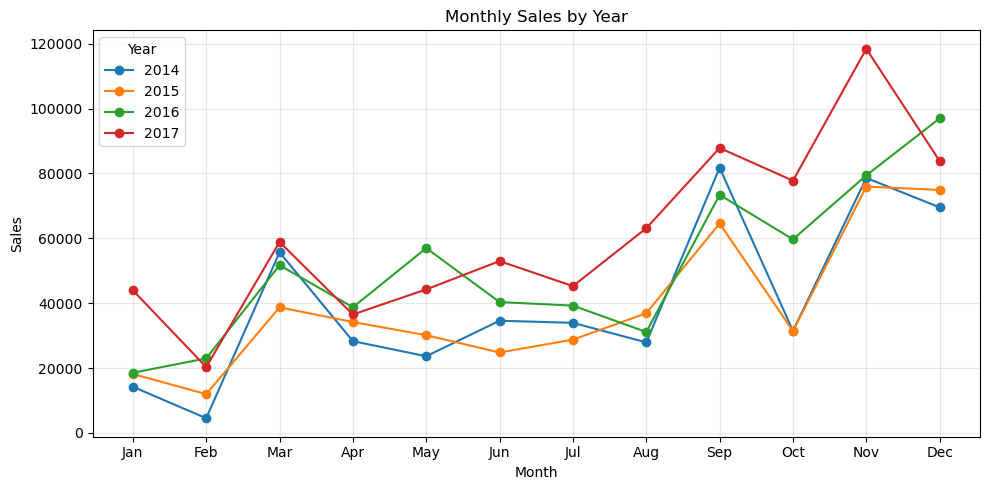

In [15]:
monthly = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
monthly.plot(marker="o", figsize=(10, 5))
plt.title("Monthly Sales by Year")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("chart_monthly_sales.png", dpi=150)
plt.show()

### Cell 2 : Sales and profit by category

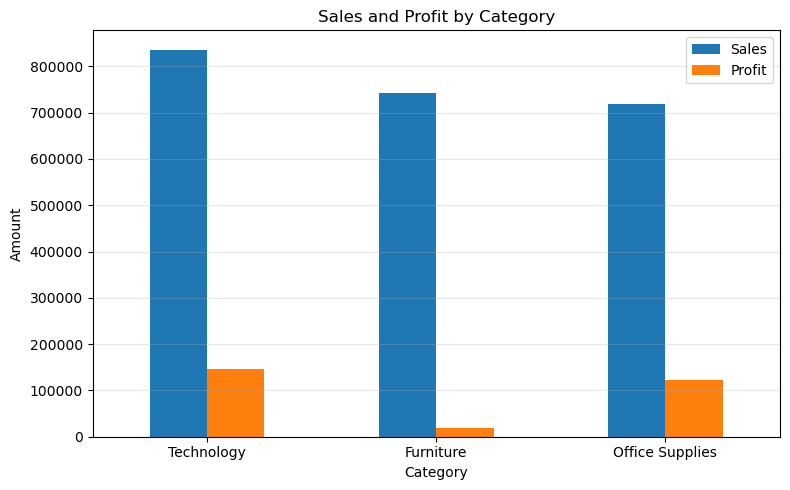

In [16]:
cat[["Sales", "Profit"]].plot(kind="bar", figsize=(8, 5))
plt.title("Sales and Profit by Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("chart_category.png", dpi=150)
plt.show()

### Cell 4: Profit by region

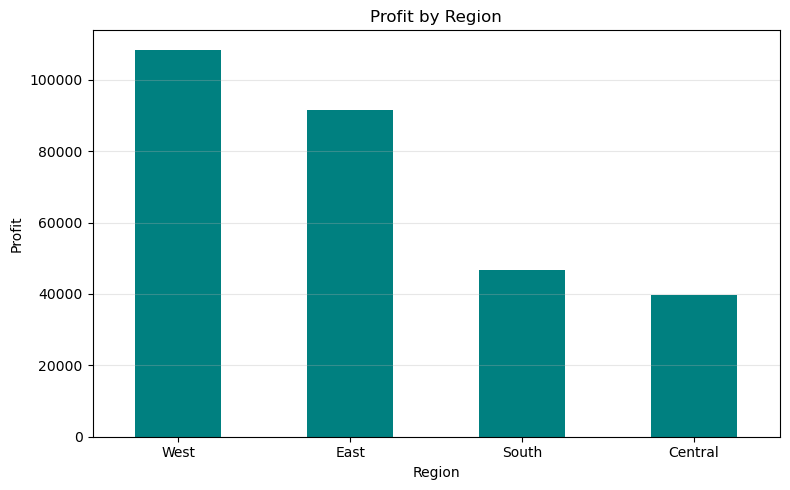

In [17]:
region["Profit"].plot(kind="bar", figsize=(8, 5), color="teal")
plt.title("Profit by Region")
plt.ylabel("Profit")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("chart_region.png", dpi=150)
plt.show()

### Cell 5: Profit margin by discount band

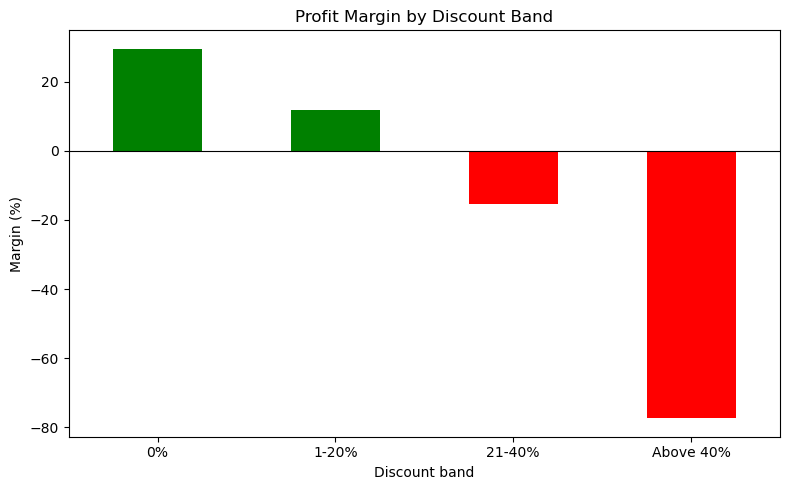

In [18]:
disc["margin_pct"].plot(kind="bar", figsize=(8, 5),
                        color=["green", "green", "red", "red"])
plt.title("Profit Margin by Discount Band")
plt.ylabel("Margin (%)")
plt.xlabel("Discount band")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart_discount_margin.png", dpi=150)
plt.show()

### Cell 6: Discount vs profit

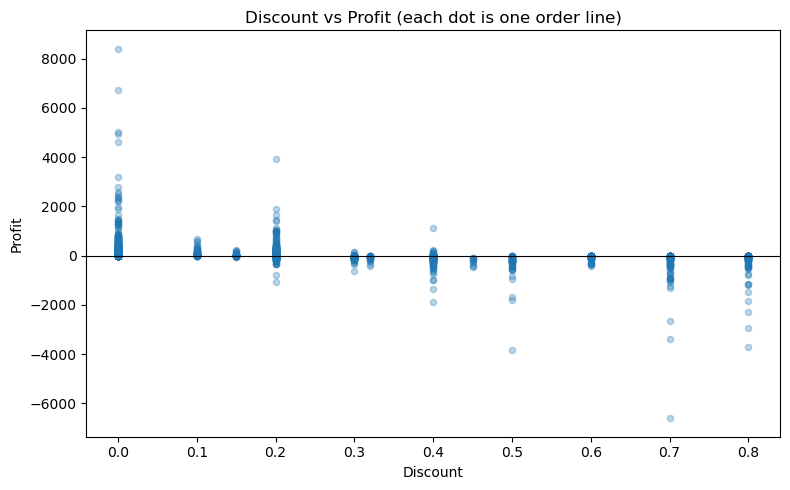

In [19]:
df.plot.scatter(x="Discount", y="Profit", alpha=0.3, figsize=(8, 5))
plt.title("Discount vs Profit (each dot is one order line)")
plt.axhline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig("chart_discount_scatter.png", dpi=150)
plt.show()

## 4. Key findings

1. **Category:**  highest sales in technology (836,154) and profit (145,455). Furniture has high sales (741,999) but earns only 18,451 in profit.
2. **Region:**  the most profitable region is West i.e (108,418). Central earns the least profit (39,706) even though its sales (501,240) are higher than South's.
3. **Loss-making products and sub-categories:** Tables (-17,725), Bookcases (-3,473) and Supplies (-1,189) lose money. The biggest product losses are the Cubify CubeX 3D Printer and the Lexmark laser printer.
4. **Seasonality and growth:** Sales peak in September, November and December every year, and February is the weakest month. Sales fell slightly in 2015, then grew in 2016 and 2017.
5. **Discount impact:** With no discount the margin is 29.5%, and with 1-20% it is 11.9%. Above 20% discount the margin becomes negative (-15.3% and -77.4%).

**Recommendations:** Review discounts above 20%, review pricing on Tables, Bookcases and the loss-making printers, and investigate why Central's margin is low.